# 현실의 데이터 29: 위성 사진 토지 분류

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/29_satellite.ipynb)

**분야**: 이미지 · 소리 · 3D &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 위성 영상 · 토지 이용 지도 · 환경 감시

> 위성 사진 한 칸이 숲일까, 밭일까, 도시일까?

**데이터**: EuroSAT (RGB, 시험 묶음 5,400장) (약 18MB). Helber et al. (2019). 유럽우주국 Sentinel-2 위성 사진 64×64, 10종류 (밭 · 숲 · 풀밭 · 고속도로 · 산업 · 목초지 · 과수원 · 주거지 · 강 · 바다/호수). Hugging Face timm/eurosat-rgb 의 시험 묶음.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 위성 사진 한 칸 (64×64) |
| ② 입력 X | 색 분포 (채널별 평균 · 히스토그램) |
| ③ 출력 y | 10가지 토지 종류 |
| ④ 평가지표 | 정확도 + 종류별 재현율 |
| ⑤ 기준선 | 가장 흔한 종류 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Helber et al. (2019) EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification, IEEE JSTARS](https://arxiv.org/abs/1709.00029)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
from PIL import Image
URL = "https://huggingface.co/api/datasets/timm/eurosat-rgb/parquet/default/test/0.parquet"
df = pd.read_parquet(download(URL, "data/eurosat_test.parquet"))
NAMES = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial", "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
imgs = np.stack([np.array(Image.open(io.BytesIO(b["bytes"])).convert("RGB")) for b in df["image"]])
labels = df["label"].values
print(imgs.shape, imgs.dtype)
print(pd.Series([NAMES[i] for i in labels]).value_counts())

(5400, 64, 64, 3) uint8
SeaLake                 609
Forest                  608
AnnualCrop              596
HerbaceousVegetation    573
Residential             554
PermanentCrop           538
River                   529
Industrial              501
Highway                 496
Pasture                 396
Name: count, dtype: int64


## 열어 보기

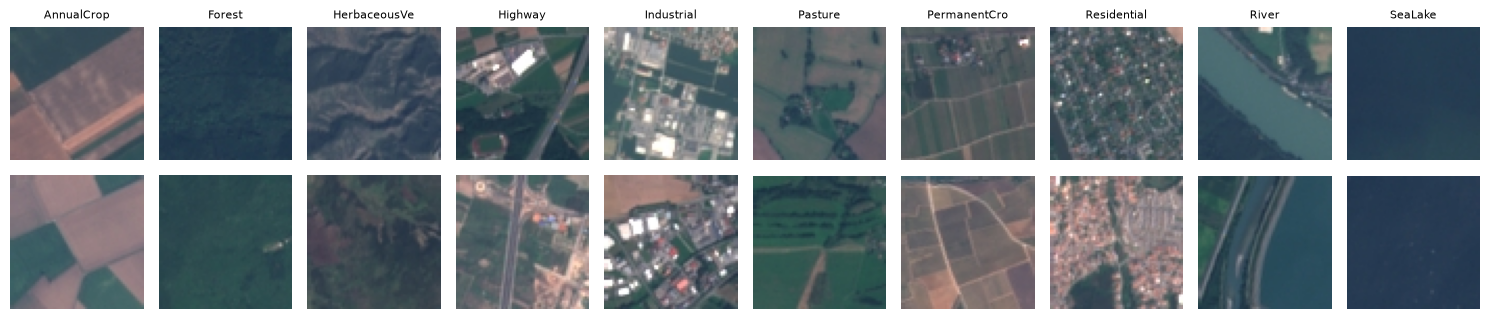

In [3]:
fig, axs = plt.subplots(2, 10, figsize=(15, 3.4))
for c in range(10):
    idx = np.where(labels == c)[0][:2]
    for r, i in enumerate(idx):
        axs[r, c].imshow(imgs[i]); axs[r, c].axis("off")
    axs[0, c].set_title(NAMES[c][:12], fontsize=8)
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 사진 → 토지 종류

색만으로 얼마나 맞힐까? 채널별 평균 · 표준편차 + 채널별 히스토그램 (8칸) 을 숫자로 만들어 랜덤 포레스트. 70% 학습 · 30% 시험.

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

def color_features(img):
    """Per-channel mean, std and 8-bin histogram of one RGB image"""
    x = img.reshape(-1, 3).astype(np.float32) / 255
    hist = [np.histogram(x[:, k], bins=8, range=(0, 1), density=True)[0] for k in range(3)]
    return np.r_[x.mean(0), x.std(0), np.concatenate(hist)]

X = np.stack([color_features(im) for im in imgs])
Xtr, Xte, ytr, yte = train_test_split(X, labels, test_size=0.3, stratify=labels, random_state=0)
m = RandomForestClassifier(400, random_state=0, n_jobs=-1).fit(Xtr, ytr)
pred = m.predict(Xte)
most = np.bincount(ytr).argmax()
print(f"baseline (always {NAMES[most]}): accuracy {np.mean(yte == most):.1%}")
print(f"random forest on colors : accuracy {np.mean(yte == pred):.1%}")
print("recall per class:", pd.Series(yte == pred).groupby([NAMES[i] for i in yte]).mean().round(2).to_dict())

baseline (always Forest): accuracy 11.2%
random forest on colors : accuracy 74.3%
recall per class: {'AnnualCrop': 0.83, 'Forest': 0.94, 'HerbaceousVegetation': 0.6, 'Highway': 0.35, 'Industrial': 0.91, 'Pasture': 0.77, 'PermanentCrop': 0.66, 'Residential': 0.84, 'River': 0.62, 'SeaLake': 0.85}


**관찰**: 숲 · 바다처럼 색이 뚜렷한 곳은 색만으로 잘 맞힌다. 고속도로 · 강처럼 '모양 (긴 선)' 이 중요한 곳은 색만으로는 어렵다. 모양까지 보려면 CNN (10주차).

## 다른 문제로 바꿔 보기

- **변화 감지**: 같은 장소의 작년 사진과 올해 사진 → 새 건물이 생겼나? 한 행 = (장소, 두 시점).
- 위성은 사람 눈에 안 보이는 파장 (근적외선 등 13개 대역) 도 찍는다. 식물은 근적외선에서 밝다. 입력에 이걸 넣으면?
- 나라가 다른 곳 (학습: 유럽, 시험: 한국) 에서도 맞힐까?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |